<a href="https://colab.research.google.com/github/labviros/computer-vision-topics/blob/version2020/lesson05-homography/sift_homography.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Implementing DLT with Normalization

###Your functions to estimate homography

In [43]:
def my_DLT(pts1,pts2):

  numpts = pts1.shape[1]

  A = np.zeros((2*numpts, 9))

  for i in range (numpts):
    A[2*i,3:6]     = -pts2[2,i]*pts1[:,i]
    A[2*i,6:9]     =  pts2[1,i]*pts1[:,i]

    A[2*i+1,0:3] =   pts2[2,i]*pts1[:,i]
    A[2*i+1,6:9]   =  -pts2[0,i]*pts1[:,i]

  # Perform SVD(A) = U.S.Vt to estimate the homography
  U,S,Vt = np.linalg.svd(A)
  h = Vt[-1,:]


  # Reshape last column of V or last line of Vt as the homography matrix
  H_matrix = h.reshape((3,3))

  return H_matrix


def normalize_points(points):
  # Calculate centroid
  cx = np.mean(points[0,:])
  cy = np.mean(points[1,:])


  # Calculate the average distance of the points having the centroid as origin
  dist = np.sqrt((points[0,:]-cx)**2 + (points[1,:]-cy)**2)
  dist_med = np.mean(dist)


  # Define the scale to have the average distance as sqrt(2)
  S = np.sqrt(2)/dist_med

  # Define the normalization matrix (similar transformation)
  Mov = np.array(([1, 0, -cx], [0, 1, -cy], [0, 0, 1]))
  Sc = np.eye(3)*S
  Sc[2,2] = 1

  T = Sc@Mov

  # Normalize points
  norm_pts = T@points

  return T, norm_pts

def my_homography(pts1,pts2):

  # Add homogeneous coordinates
  pts1 = pts1.T
  pts1 = np.vstack((pts1, np.ones(pts1.shape[1])))
  pts2 = pts2.T
  pts2 = np.vstack((pts2, np.ones(pts2.shape[1])))

  # Normalize points
  T1, p1 = normalize_points(pts1)
  T2, p2 = normalize_points(pts2)

  # Perform DLT and obtain normalized matrix
  DLT = my_DLT(p1, p2)

  # Denormalize the homography matrix
  H = np.linalg.inv(T2) @ DLT @ T1

  return H

#Using SIFT to estimate Homography between images and to warp the first image

<Figure size 640x480 with 0 Axes>

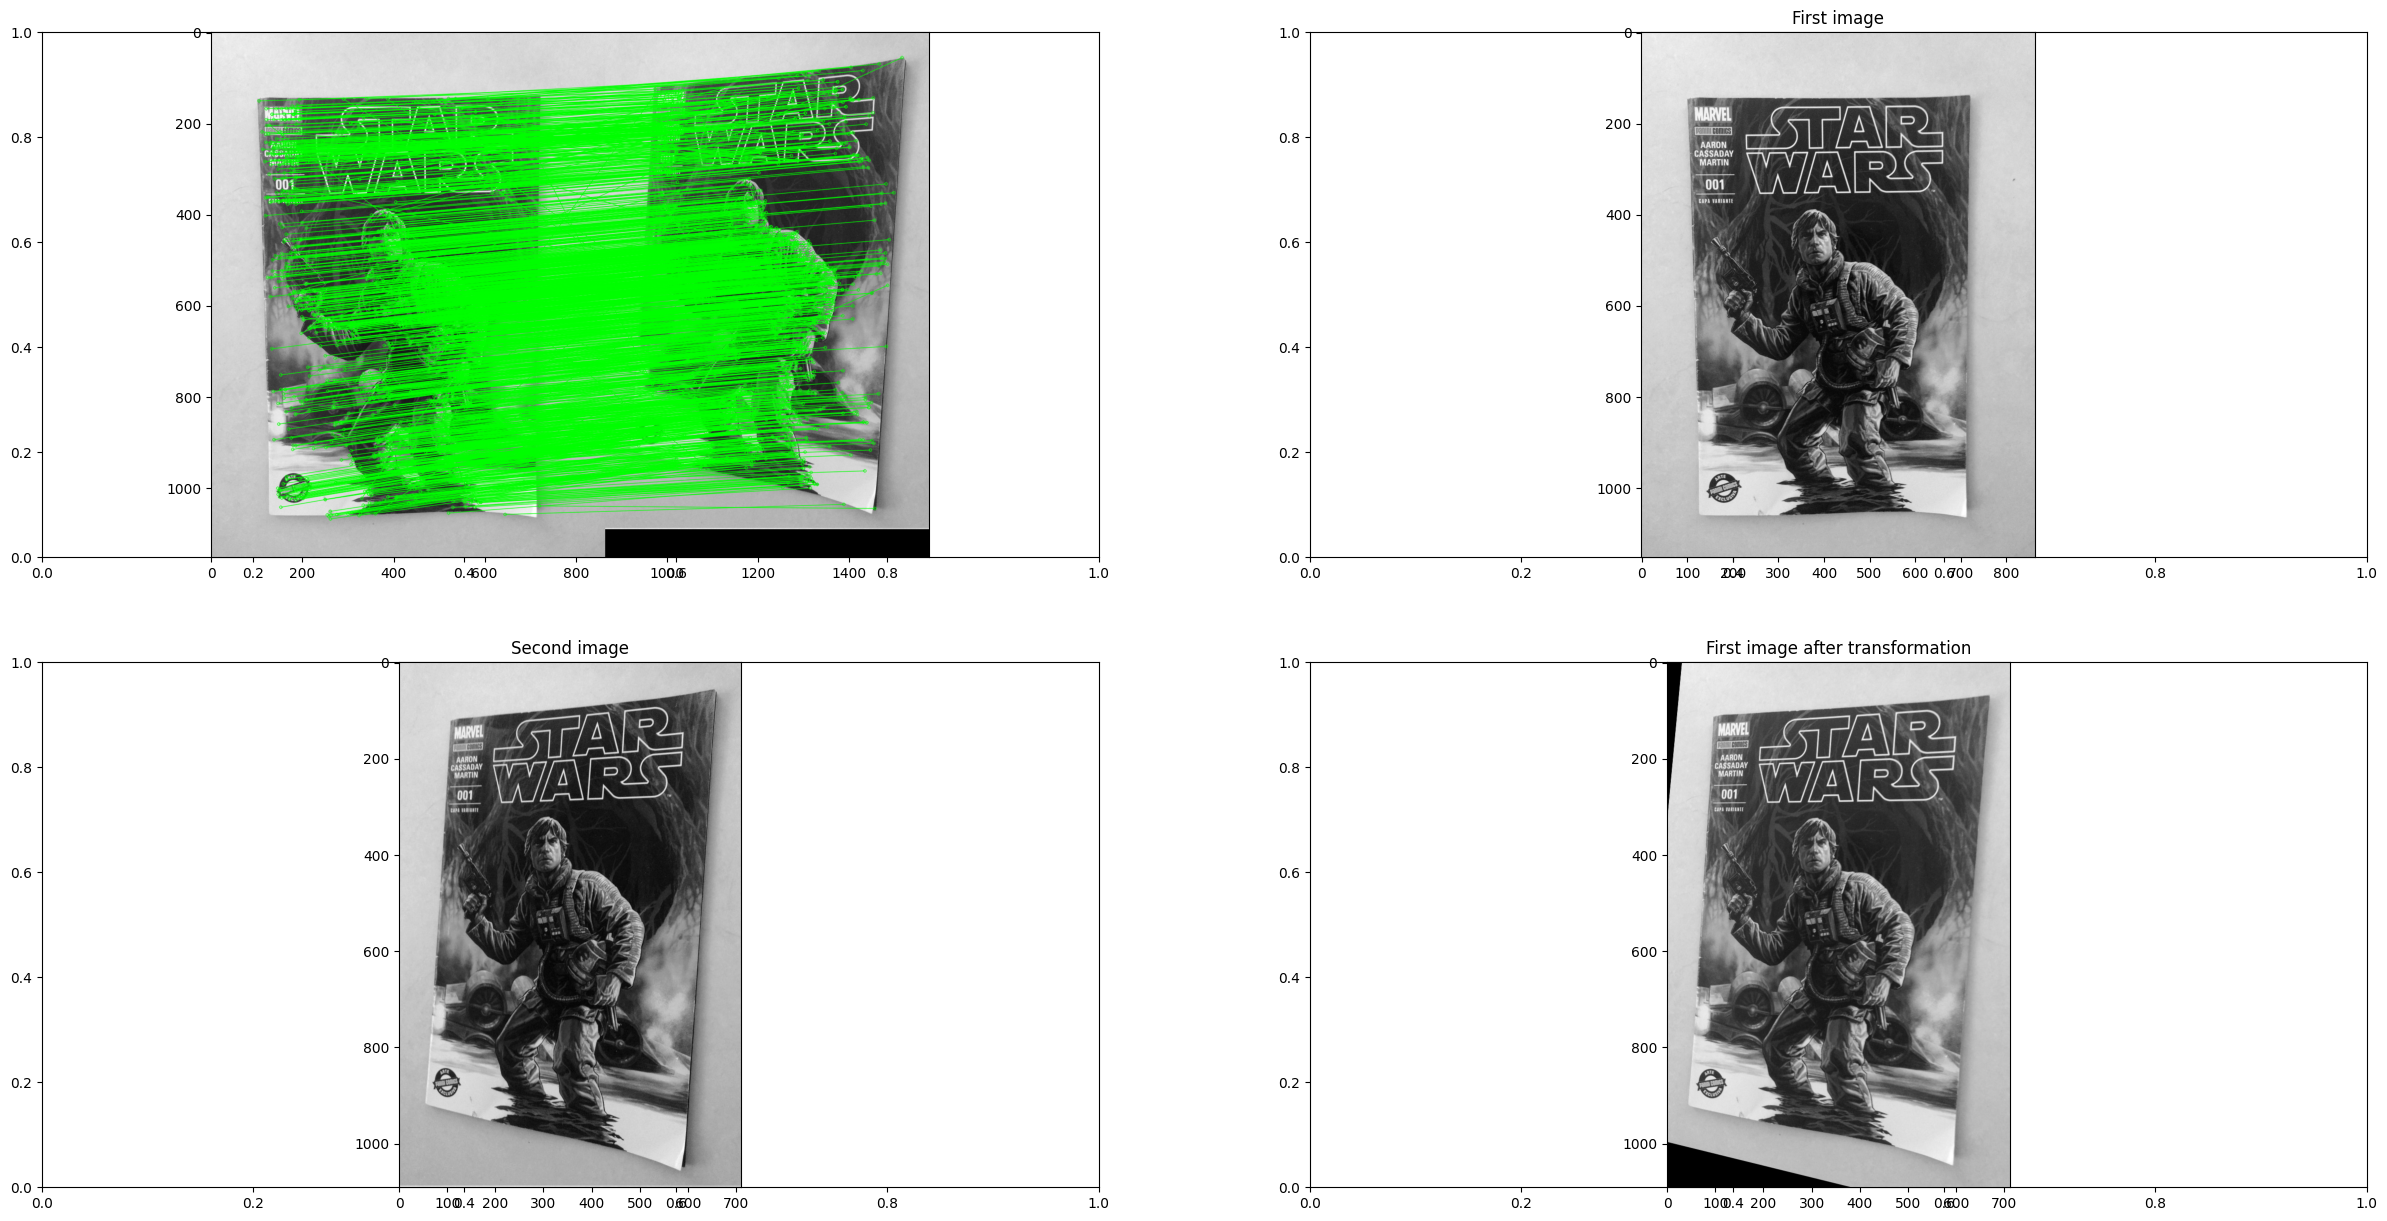

In [44]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
import imutils



MIN_MATCH_COUNT = 10
img1 = cv.imread('comicsStarWars01.jpg',0)          # queryImage
img2 = cv.imread('comicsStarWars02.jpg',0) # trainImage

#img1 = imutils.rotate_bound(img1,180)

# Initiate SIFT detector
#sift = cv.xfeatures2d.SIFT_create()
sift = cv.SIFT_create()
# find the keypoints and descriptors with SIFT

kp1, des1 = sift.detectAndCompute(img1,None)
kp2, des2 = sift.detectAndCompute(img2,None)


# FLANN stands for Fast Library for Approximate Nearest Neighbors.
# It contains a collection of algorithms optimized for fast nearest neighbor
# search in large datasets and for high dimensional features.
# It works faster than BFMatcher for large datasets.
# The variable index_params specifies the algorithm to be used, its related parameters etc.
# For algorithms like SIFT, SURF etc. you can pass following:
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
# The variable search_params specifies the number of times the trees in the index should
# be recursively traversed. Higher values gives better precision, but also takes more time.
search_params = dict(checks = 50)
flann = cv.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1,des2,k=2)
#bf = cv.BFMatcher()
#matches = bf.knnMatch(des1,des2,k=2)plt.imshow(img3, 'gray')



# store all the good matches as per Lowe's ratio test.
good = []
for m,n in matches:
    if m.distance < 0.75*n.distance:
        good.append(m)


if len(good)>MIN_MATCH_COUNT:
    src_pts = np.float32([ kp1[m.queryIdx].pt for m in good ])
    dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good ])
    #matchesMask = mask.ravel().tolist()



    #####################################################
    # Substitute OpenCv function for your homography function

    # M, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC,5.0)
    M = my_homography(src_pts, dst_pts)
    #####################################################

    img4 = cv.warpPerspective(img1, M, (img2.shape[1],img2.shape[0])) #, None) #, flags[, borderMode[, borderValue]]]]	)


matchesMask = None
draw_params = dict(matchColor = (0,255,0), # draw matches in green color
                   singlePointColor = None,
                   matchesMask = matchesMask, # draw only inliers
                   flags = 2)
img3 = cv.drawMatches(img1,kp1,img2,kp2,good,None,**draw_params)


fig = plt.figure()
fig, axs = plt.subplots(2,2,figsize=(30,15))
ax1 = fig.add_subplot(2,2,1)
plt.imshow(img3, 'gray')
ax1 = fig.add_subplot(2,2,2)
plt.title('First image')
plt.imshow(img1,'gray')
ax1 = fig.add_subplot(2,2,3)
plt.title('Second image')
plt.imshow(img2,'gray')
ax1 = fig.add_subplot(2,2,4)
plt.title('First image after transformation')
plt.imshow(img4,'gray')
plt.show()